In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
from plotly.subplots import make_subplots

In [3]:
columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

iris = pd.read_csv("iris.data", names=columns)

print(iris)

     sepal_length  sepal_width  petal_length  petal_width         species
0             5.1          3.5           1.4          0.2     Iris-setosa
1             4.9          3.0           1.4          0.2     Iris-setosa
2             4.7          3.2           1.3          0.2     Iris-setosa
3             4.6          3.1           1.5          0.2     Iris-setosa
4             5.0          3.6           1.4          0.2     Iris-setosa
..            ...          ...           ...          ...             ...
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica

[150 rows x 5 columns]


In [4]:
iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB


Text(0, 0.5, 'Długość działki kwiatka')

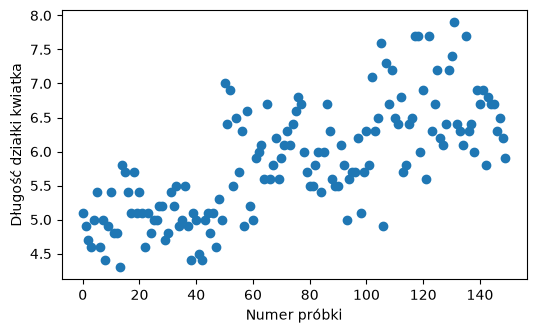

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(x=iris.index, y=iris["sepal_length"])
ax.set_xlabel("Numer próbki")
ax.set_ylabel("Długość działki kwiatka")

In [7]:
px.scatter(iris, y="sepal_length", color="species")

sepal_length przymuje wartości od 4.3 do 7.9

In [ ]:
iris_setosa = iris[(iris["species"] == "Iris-setosa")]
iris_setosa_num = (iris["species"] == "Iris-setosa").sum()
print(iris_setosa_num)
iris_setosa_small_num = ((iris["species"] == "Iris-setosa") & (iris["sepal_width"] < 2.5)).sum()
print("Ilość kwiatek z długością działki < 2.5:", iris_setosa_small_num)

50
Ilość kwiatek z długością działki < 2.5: 1


In [ ]:
sepal_width_max = np.ceil(iris["sepal_width"].max())
sepal_width_min = np.floor(iris["sepal_width"].min())
steps = np.arange(sepal_width_min, sepal_width_max, 0.5)

(array([ 1.,  1., 27., 17.,  4.]),
 array([2. , 2.5, 3. , 3.5, 4. , 4.5]),
 <BarContainer object of 5 artists>)

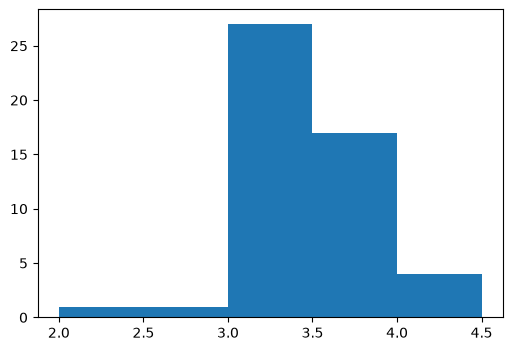

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.hist(iris_setosa["sepal_width"], bins=steps)

In [ ]:
fig = px.histogram(
    iris_setosa,
    x="sepal_width"
)

fig.update_traces(
    xbins=dict(
        start=steps[0],
        end=steps[-1],
        size=0.5
    )
)

Indeed, jest to histogram

In [ ]:
plot_sepal = px.scatter(iris, x="sepal_length", y="sepal_width", color="species", size="petal_length")
plot_petal = px.scatter(iris, x="petal_length", y="petal_width", color="species", size="petal_width")
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Sepal length vs sepal width",
                    "Petal length vs petal width")
)

for trace in plot_sepal.data:
    fig.add_trace(trace, row=1, col=1)

for trace in plot_petal.data:
    fig.add_trace(trace, row=1, col=2)

fig.show()

Nie ma sensu łączyć linią obserwacje, poniewaz kazda kropka to po prostu odzielny kwiatek.
Nie ma tu zadnej zalezności pomiędzy pojedyńczymi kwiatkami.

In [ ]:
plot_length = px.scatter(iris, x="petal_length", y="sepal_length", color="species", size="sepal_length")
plot_width = px.scatter(iris, x="petal_width", y="sepal_width", color="species", size="sepal_width")
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Petal length vs sepal length",
                    "Petal width vs sepal width")
)

for trace in plot_length.data:
    fig.add_trace(trace, row=1, col=1)

for trace in plot_width.data:
    fig.add_trace(trace, row=1, col=2)

fig.show()

In [ ]:
plot_opp1 = px.scatter(iris, x="petal_length", y="sepal_width", color="species", size="sepal_length")
plot_opp2 = px.scatter(iris, x="petal_width", y="sepal_length", color="species", size="sepal_width")
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Petal length vs sepal width",
                    "Petal width vs sepal length")
)

for trace in plot_opp1.data:
    fig.add_trace(trace, row=1, col=1)

for trace in plot_opp2.data:
    fig.add_trace(trace, row=1, col=2)

fig.show()

In [ ]:
print(iris_setosa["petal_length"].max())

1.9


Na wszystkich wykresach gatunek "iris setosa" jest widocznie odizolowany od pozostałych dwóch.
Bardzo harakterystyczne jest to ze ten gatunek ma mniejsze płatki jak i w szerokości, tak i w wysokości,
gdzy wymiary działki są +- takie same we wszystkich gatunkach.
Regułą rozpoznającą tan gatunek moe być własność petal_length, jeśli jest ona < 2, to najprawdopodobniej kwiatek nalezy do gatunku "iris-setosa"

In [ ]:
attributes = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=attributes
)

for i, attribute in enumerate(attributes):
    plot = px.violin(
        iris,
        x="species",
        y=attribute,
        color="species",
        box=True,
        points="all"
    )

    row = i // 2 + 1
    col = i % 2 + 1

    for trace in plot.data:
        fig.add_trace(trace, row=row, col=col)

fig.update_layout(
    height=750,
    width=1000,
    showlegend=False
)

fig.show()

Violin plot to połączenie wykresu pudełkowego oraz wykresu gęstości (który jest po obu stronach)